# Imports

In [1]:
%pip install -q speechbrain==1.1.2 

Note: you may need to restart the kernel to use updated packages.


In [19]:
import copy
import json
import math
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torch.nn.functional as F
import xgboost as xgb

from scipy.signal import resample_poly
from scipy.special import softmax
from sklearn.metrics import f1_score, roc_auc_score, roc_curve
from speechbrain.inference.classifiers import EncoderClassifier
from speechbrain.utils.fetching import FetchConfig
from torch import nn

print ("Device:", "GPU" if torch.cuda.is_available() else "CPU")

Device: GPU


# Data prepare

In [ ]:
features_file = Path("/kaggle/working/ecapa_features/features_3s.pt")  # результат extract_features_to_disk
split_file = Path("/kaggle/working/audiolid_split.pkl")                # таблица выборок из audiolid.ipynb
output = Path("/kaggle/working/ecapa_results")
device = "cuda:0" if torch.cuda.is_available() else "cpu"
labels = ["ru", "ar", "unknown"]

saved = torch.load(features_file)
feats = saved["feats"].float()
rows = pd.DataFrame({"audio_path": saved["paths"], "split": saved["split"], "label": saved["label"]})

# Источник и язык берём из таблицы выборок: по ним видно, где ошибки — et, fi, шум, музыка.
table = pd.read_pickle(split_file).reset_index(drop=True) if split_file.exists() else None
if table is not None and table["audio_path"].astype(str).tolist() == rows["audio_path"].tolist():
    rows["group"] = np.where(table["source"] == "commonvoice", table["locale"], table["source"])
else:
    print("Таблица выборок не совпадает с файлом признаков — разбивка по языкам будет только по меткам")
    rows["group"] = rows["label"]

usable = ~feats.isnan().any(dim=1)  # клипы, которые не удалось прочитать
y_all = torch.tensor(rows["label"].map(labels.index).to_numpy())


def split_mask(name):
    return torch.from_numpy((rows["split"] == name).to_numpy()) & usable


def split_data(name):
    mask = split_mask(name)
    return feats[mask], y_all[mask]


pd.crosstab(rows.loc[usable.numpy(), "label"], rows.loc[usable.numpy(), "split"])[["train", "dev", "test"]]

split,train,dev,test
label,,,
ar,11030,220,216
ru,33586,729,732
unknown,10065,3622,3610


In [20]:
UNKNOWN = labels.index("unknown")
TARGETS = [labels.index("ru"), labels.index("ar")]
EVAL_SPLITS = ("dev", "test")
ROC_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]  # ru, ar, unknown
evaluations = {}  # имя модели → порог, метрики и таблица предсказаний


def score_splits(predict):
    """Адаптер predict(X) → выходы модели [N, 3], применённый к признакам dev и test (X — numpy [N, 512])."""
    return {split: predict(split_data(split)[0].numpy()) for split in EVAL_SPLITS}


def to_probs(scores, kind="probs"):
    """Выходы модели → вероятности [N, 3] в порядке labels.

    kind: "probs" — вероятности, "logits" — сырые выходы слоя, "log_probs" — логарифмы вероятностей,
    "labels" — только индексы классов (порог и ROC для них вырождаются).
    """
    if hasattr(scores, "detach"):  # тензор torch, в том числе на GPU
        scores = scores.detach().float().cpu().numpy()
    scores = np.asarray(scores, dtype=np.float64)
    if kind == "labels":
        return np.eye(len(labels))[scores.astype(int).ravel()]
    if kind in ("logits", "log_probs"):  # для log_probs softmax — это exp с перенормировкой
        return softmax(scores, axis=1)
    if kind == "probs":
        if not np.allclose(scores.sum(axis=1), 1, atol=1e-3):
            raise ValueError("Строки не суммируются в 1 — похоже на logits или log_probs, укажите kind")
        return scores / scores.sum(axis=1, keepdims=True)
    raise ValueError(f"Неизвестный kind={kind!r}: probs, logits, log_probs или labels")


def decide(P, threshold):
    """Argmax; если победил ru или ar, но уверенность ниже порога — unknown."""
    pred = P.argmax(axis=1)
    return np.where((pred != UNKNOWN) & (P.max(axis=1) < threshold), UNKNOWN, pred)


def pick_threshold(P, y, min_coverage=0.9):
    """Правило, как для исходной ECAPA: поднимаем порог, пока он отсекает unknown,
    а каждый целевой язык по-прежнему принимается не реже min_coverage."""
    pred, score = P.argmax(axis=1), P.max(axis=1)
    target_wins = pred != UNKNOWN
    threshold = 0.0
    for s in np.unique(score[(y == UNKNOWN) & target_wins]):
        accepted = target_wins & (score > s)
        if min(accepted[y == k].mean() for k in TARGETS) < min_coverage:
            break
        threshold = float(np.nextafter(s, 1.0))  # отклоняем и саму оценку s
    return threshold


def metrics(y, pred):
    accepted = pred != UNKNOWN
    rejected = ~accepted
    return {
        "клипов": len(y),
        "macro_f1": float(f1_score(y, pred, labels=list(range(len(labels))), average="macro", zero_division=0)),
        **{f"coverage_{labels[k]}": float(accepted[y == k].mean()) for k in TARGETS},
        "unknown_FAR": float(accepted[y == UNKNOWN].mean()),
        "ru/ar_FRR": float(rejected[y != UNKNOWN].mean()),
    }


def evaluate(name, scores, kind="probs", info=None, min_coverage=0.9, show=True):
    """Оценка любой модели по её выходам: порог по dev, метрики dev/test, файлы в output.

    scores — {"dev": [N, 3], "test": [N, 3]} в порядке split_data (так возвращает score_splits).
    Пишет <name>_predictions.jsonl и <name>_summary.json; info — что ещё добавить в summary.
    """
    P, y = {}, {}
    for split in EVAL_SPLITS:
        P[split], y[split] = to_probs(scores[split], kind), split_data(split)[1].numpy()
        if P[split].shape != (len(y[split]), len(labels)) or not np.isfinite(P[split]).all():
            raise ValueError(f"{name}/{split}: нужны конечные выходы формы {(len(y[split]), len(labels))}, "
                             f"пришло {P[split].shape}")
    threshold = pick_threshold(P["dev"], y["dev"], min_coverage)  # только по dev; на test ничего не подбираем
    result = {(split, rule): metrics(y[split], decide(P[split], t))
              for split in EVAL_SPLITS for rule, t in (("argmax", 0.0), ("с порогом", threshold))}
    predictions = pd.concat([
        rows[split_mask(split).numpy()].assign(
            **{f"p_{label}": P[split][:, k] for k, label in enumerate(labels)},
            prediction=[labels[k] for k in decide(P[split], threshold)],
        )
        for split in EVAL_SPLITS
    ])
    evaluations[name] = {"threshold": threshold, "metrics": result, "predictions": predictions}

    output.mkdir(parents=True, exist_ok=True)
    predictions.to_json(output / f"{name}_predictions.jsonl", orient="records", lines=True, force_ascii=False)
    summary = {"model": name, "labels": labels, "threshold": threshold, "min_coverage": min_coverage,
               "features": str(features_file), **(info or {}),
               "metrics": {f"{split}/{rule}": values for (split, rule), values in result.items()}}
    (output / f"{name}_summary.json").write_text(json.dumps(
        summary, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o),
    ), encoding="utf-8")

    print(f"{name}: порог по dev {threshold:.4f}")
    display(pd.DataFrame(result).T.round(3))
    print("Доля верных ответов с порогом по языкам и источникам")
    display(predictions.assign(верно=predictions["prediction"] == predictions["label"])
            .groupby(["label", "group", "split"])["верно"].agg(клипов="size", доля="mean")
            .unstack("split").round(3))
    test_pred = predictions[predictions["split"] == "test"]
    display(pd.crosstab(test_pred["label"], test_pred["prediction"])
            .reindex(index=labels, columns=labels, fill_value=0)
            .rename_axis(index="Метка (test)", columns="Предсказание"))

    # Show ROC curves for each class
    roc_for(name, split="test")
    return evaluations[name]


def load_predictions(name):
    """Таблица предсказаний модели: из памяти, а после перезапуска ядра — из <name>_predictions.jsonl."""
    if name in evaluations:
        return evaluations[name]["predictions"]
    return pd.read_json(output / f"{name}_predictions.jsonl", lines=True)


def plot_roc(P, y, groups=None, title="ROC", save_to=None):
    """ROC «класс против остальных»: P — вероятности [N, 3], y — индексы классов, groups — источник клипа."""
    P, y = np.asarray(P, dtype=float), np.asarray(y)
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot([0, 1], [0, 1], color="#c3c2b7", linewidth=1, label="случайный классификатор")
    aucs = {}
    for k, (name, color) in enumerate(zip(labels, ROC_COLORS)):
        positive = y == k
        fpr, tpr, _ = roc_curve(positive, P[:, k])
        aucs[name] = roc_auc_score(positive, P[:, k])
        ax.plot(fpr, tpr, color=color, linewidth=2, solid_capstyle="round",
                label=f"{name} vs остальные · AUC {aucs[name]:.3f} · n={positive.sum()}")
    aucs["macro"] = roc_auc_score(y, P, multi_class="ovr", average="macro")
    ax.set(xlim=(0, 1), ylim=(0, 1.01), aspect="equal", xlabel="False positive rate",
           ylabel="True positive rate", title=f"{title} · macro AUC {aucs['macro']:.3f}")
    ax.grid(color="#e6e5e0", linewidth=1)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower right", frameon=False)
    fig.tight_layout()
    if save_to is not None:
        fig.savefig(save_to, dpi=150)
    plt.show()
    print(pd.Series(aucs, name="ROC AUC").round(3).to_string())

    if groups is not None:  # каждый источник unknown отдельно: насколько p_unknown отделяет его от ru и ar
        groups, target = np.asarray(groups), y != UNKNOWN
        by_group = {}
        for group in np.unique(groups[~target]):
            own = (groups == group) & ~target
            by_group[group] = {"клипов": int(own.sum()), "AUC против ru+ar": roc_auc_score(
                np.r_[np.zeros(target.sum()), np.ones(own.sum())], np.r_[P[target, UNKNOWN], P[own, UNKNOWN]])}
        print("\nunknown по источникам")
        print(pd.DataFrame(by_group).T.astype({"клипов": int}).round(3).to_string())
    return aucs


def roc_for(name, split="test"):
    """ROC модели из evaluate или из файлов старых ячеек оценки (head, xgb, logreg)."""
    preds = load_predictions(name)
    preds = preds[preds["split"] == split]
    return plot_roc(preds[[f"p_{label}" for label in labels]].to_numpy(),
                    preds["label"].map(labels.index).to_numpy(),
                    preds["group"].to_numpy() if "group" in preds else None,
                    title=f"ROC {name} на {split}, one-vs-rest", save_to=output / f"{name}_roc_{split}.png")


def compare(metric="macro_f1", names=None):
    """metric по моделям — из всех <name>_summary.json в output, в том числе от старых ячеек оценки."""
    names = names or sorted(f.name.removesuffix("_summary.json") for f in output.glob("*_summary.json"))
    columns = {}
    for name in names:
        summary = json.loads((output / f"{name}_summary.json").read_text(encoding="utf-8"))
        columns[name] = {key: values[metric] for key, values in summary["metrics"].items()}
    return pd.DataFrame(columns).round(3)


def _macro_f1(C):
    """macro-F1 из матриц ошибок [..., 3, 3]: строки — истинный класс, столбцы — ответ."""
    tp = np.diagonal(C, axis1=-2, axis2=-1)
    denom = C.sum(axis=-2) + C.sum(axis=-1)  # 2·tp + fp + fn
    return np.divide(2 * tp, denom, out=np.zeros(denom.shape), where=denom > 0).mean(axis=-1)


def speaker_monte_carlo(*names, n=1000, seed=0):
    """macro-F1 с 95%-интервалом: дикторы пересэмплируются целиком (у MUSAN единица — запись).

    Для двух моделей добавляется интервал их разницы на одних и тех же выборках дикторов.
    """
    speaker = table.set_index("audio_path")["speaker_id"] if table is not None else pd.Series(dtype=object)
    speaker = speaker[~speaker.index.duplicated()]
    preds = {name: load_predictions(name).set_index("audio_path") for name in names}
    rng = np.random.default_rng(seed)
    out = []
    for split in EVAL_SPLITS:
        first = preds[names[0]]
        paths = first.index[first["split"] == split]
        for name in names[1:]:
            if not paths.isin(preds[name].index).all():
                raise ValueError(f"{names[0]} и {name} оценены на разных клипах {split}")
        units = pd.Series(paths, index=paths).map(speaker).fillna(pd.Series(paths, index=paths))
        codes, uniques = pd.factorize(units)
        weights = rng.multinomial(len(uniques), np.full(len(uniques), 1 / len(uniques)), size=n)
        for rule in ("argmax", "с порогом"):
            point, boot = {}, {}
            for name in names:
                part = preds[name].loc[paths]
                y = part["label"].map(labels.index).to_numpy()
                pred = (part[[f"p_{label}" for label in labels]].to_numpy().argmax(axis=1) if rule == "argmax"
                        else part["prediction"].map(labels.index).to_numpy())
                counts = np.zeros((len(uniques), len(labels), len(labels)))
                np.add.at(counts, (codes, y, pred), 1)
                point[name] = _macro_f1(counts.sum(axis=0))
                boot[name] = _macro_f1((weights @ counts.reshape(len(uniques), -1)).reshape(n, *counts.shape[1:]))
            if len(names) == 2:
                point[" − ".join(names)] = point[names[0]] - point[names[1]]
                boot[" − ".join(names)] = boot[names[0]] - boot[names[1]]
            for name in point:
                low, high = np.percentile(boot[name], [2.5, 97.5])
                out.append({"split": split, "правило": rule, "модель": name,
                            "macro_f1": point[name], "2.5%": low, "97.5%": high})
    return pd.DataFrame(out).set_index(["split", "правило", "модель"]).round(3)

# Train + Eval

In [22]:
STOP_ON = "macro_f1"  # "loss" — dev loss со сбалансированными классами, "macro_f1" — dev macro-F1 по argmax

X_train, y_train = (t.numpy() for t in split_data("train"))
X_dev, y_dev = (t.numpy() for t in split_data("dev"))


def balanced_weights(y):
    """Вес клипа обратно пропорционален размеру класса: каждый класс в сумме весит одинаково."""
    counts = np.bincount(y, minlength=len(labels))
    return (len(y) / (len(labels) * counts))[y]


def macro_f1_error(y_true, y_score):
    """1 − macro-F1 по argmax: при ранней остановке XGBoost минимизирует метрику, поэтому «1 −»."""
    pred = np.asarray(y_score).reshape(len(y_true), -1).argmax(axis=1)
    return 1 - f1_score(np.asarray(y_true).astype(int), pred, labels=list(range(len(labels))),
                        average="macro", zero_division=0)


xgb_params = dict(
    n_estimators=500,          # верхняя граница: сколько деревьев нужно, решит ранняя остановка по dev
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,              # каждое дерево видит 80% клипов
    colsample_bytree=0.5,       # и половину из 512 признаков
    reg_lambda=1.0,
    objective="multi:softprob",
    early_stopping_rounds=500,  # стоп, если метрика на dev не улучшается 100 итераций подряд
    tree_method="hist",
    device="cuda" if torch.cuda.is_available() else "cpu",
    random_state=0,
)
booster = xgb.XGBClassifier(**xgb_params, eval_metric="mlogloss" if STOP_ON == "loss" else macro_f1_error)
if not hasattr(booster, "_estimator_type"):  # XGBoost 2.0 с новым scikit-learn иначе не принимает свою метрику
    booster._estimator_type = "classifier"

start = perf_counter()
booster.fit(
    X_train, y_train, sample_weight=balanced_weights(y_train),
    eval_set=[(X_dev, y_dev)],
    # Для loss — веса и на dev: unknown там около 80%, а остановка должна смотреть на все классы поровну.
    # macro-F1 и так считает классы поровну, ему веса не нужны.
    sample_weight_eval_set=[balanced_weights(y_dev)] if STOP_ON == "loss" else None,
    verbose=100,
)
booster.set_params(device="cpu")  # предсказывать на CPU: деревьям это быстро, и не нужно копировать данные на GPU
dev_f1 = f1_score(y_dev, booster.predict(X_dev), labels=list(range(len(labels))), average="macro", zero_division=0)
print(f"Лучшая итерация {booster.best_iteration} (остановка по {STOP_ON}): "
      f"dev macro-F1 без порога={dev_f1:.3f}; обучение {perf_counter() - start:.0f} с")

[0]	validation_0-mlogloss:1.07175	validation_0-macro_f1_error:0.40154
[100]	validation_0-mlogloss:0.52085	validation_0-macro_f1_error:0.32842
[200]	validation_0-mlogloss:0.59595	validation_0-macro_f1_error:0.35213
[300]	validation_0-mlogloss:0.67734	validation_0-macro_f1_error:0.36574
[400]	validation_0-mlogloss:0.74573	validation_0-macro_f1_error:0.37205
[499]	validation_0-mlogloss:0.80966	validation_0-macro_f1_error:0.37592
Лучшая итерация 31 (остановка по macro_f1): dev macro-F1 без порога=0.679; обучение 21 с


xgb: порог по dev 0.4518


клипов  macro_f1  coverage_ru  coverage_ar  unknown_FAR  \
dev  argmax     4571.0     0.679        0.971        0.964        0.268   
     с порогом  4571.0     0.731        0.947        0.900        0.182   
test argmax     4558.0     0.681        0.975        0.954        0.263   
     с порогом  4558.0     0.726        0.947        0.917        0.187   

                ru/ar_FRR  
dev  argmax         0.031  
     с порогом      0.064  
test argmax         0.030  
     с порогом      0.060

Доля верных ответов с порогом по языкам и источникам


клипов           доля       
split                dev    test    dev   test
label   group                                 
ar      ar         219.0   216.0  0.881  0.898
        librivox     1.0     NaN  1.000    NaN
ru      librivox     3.0     3.0  1.000  1.000
        ru         726.0   729.0  0.938  0.930
unknown et        2518.0  2520.0  0.791  0.782
        fi         488.0   478.0  0.783  0.785
        librivox    57.0    58.0  0.614  0.672
        music      233.0   230.0  0.987  0.991
        noise      326.0   324.0  0.997  0.997

Предсказание,ru,ar,unknown
Метка (test),,,
ru,681,12,39
ar,4,194,18
unknown,95,579,2936


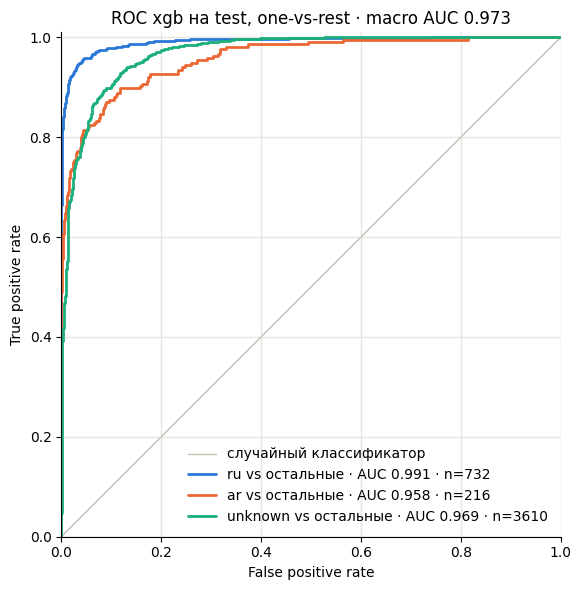

ru         0.991
ar         0.958
unknown    0.969
macro      0.973

unknown по источникам
          клипов  AUC против ru+ar
et          2520             0.963
fi           478             0.968
librivox      58             0.928
music        230             0.997
noise        324             0.998


In [23]:
evaluate("xgb", score_splits(booster.predict_proba), kind="probs", show=True,
         info={"best_iteration": booster.best_iteration, "stop_on": STOP_ON, **xgb_params})
booster.get_booster()[: booster.best_iteration + 1].save_model(str(output / "xgb_model.json"))

In [25]:
speaker_monte_carlo("xgb", n=1000, seed=0)

macro_f1   2.5%  97.5%
split правило   модель                        
dev   argmax    xgb        0.679  0.652  0.703
      с порогом xgb        0.731  0.703  0.755
test  argmax    xgb        0.681  0.655  0.706
      с порогом xgb        0.726  0.699  0.751